# Changing the folder Path


In [49]:
import os

# Change this to your actual folder path
os.chdir('/Users/adityayadav3238')

print("Now working in:", os.getcwd())

Now working in: /Users/adityayadav3238


# Loading PIZZA HUT SALES Dataset

In [50]:
import pandas as pd
df = pd.read_csv("pizza_sales.csv")

# Handle inconsistent date format

In [51]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', dayfirst=True)

# Extract features

In [52]:
df['day_of_week'] = df['order_date'].dt.dayofweek
df['month'] = df['order_date'].dt.month

# Convert order_time (if applicable)

In [53]:
df['order_time'] = pd.to_datetime(df['order_time'], format='%H:%M:%S', errors='coerce')
df['hour'] = df['order_time'].dt.hour

In [64]:
df = df.drop(columns=['order_date', 'order_time'], errors='ignore')

# Ensure all categorical features are encoded
categorical_cols = df.select_dtypes(include='object').columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)


# Define X and y

In [65]:
X = df.drop(['total_price'], axis=1)
X = X.select_dtypes(include=['number'])  # keep only numeric
y = df['total_price']

# Train-test split and model training

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [67]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

# Checking Model Performance

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))



#Model Performs quite well-model explains 98.5% of the variance in sales

R2 Score: 0.9844594929430992
RMSE: 0.5576783841698374


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [71]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Plot: Actual vs Predicted

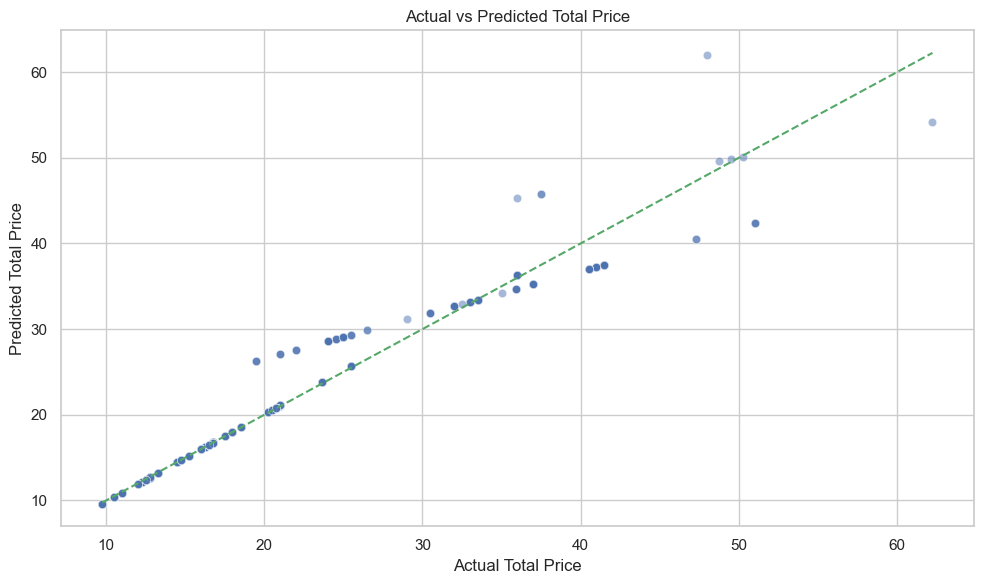

In [75]:
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='g', linestyle='--')
plt.xlabel('Actual Total Price')
plt.ylabel('Predicted Total Price')
plt.title('Actual vs Predicted Total Price')
plt.tight_layout()
plt.show()

Each dot represents a pizza order from the test data.

The red dashed line indicates perfect prediction

In [72]:
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))

R2 Score: 0.9844594929430992
RMSE: 0.5576783841698374


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


# Histogram of Predicted Sales

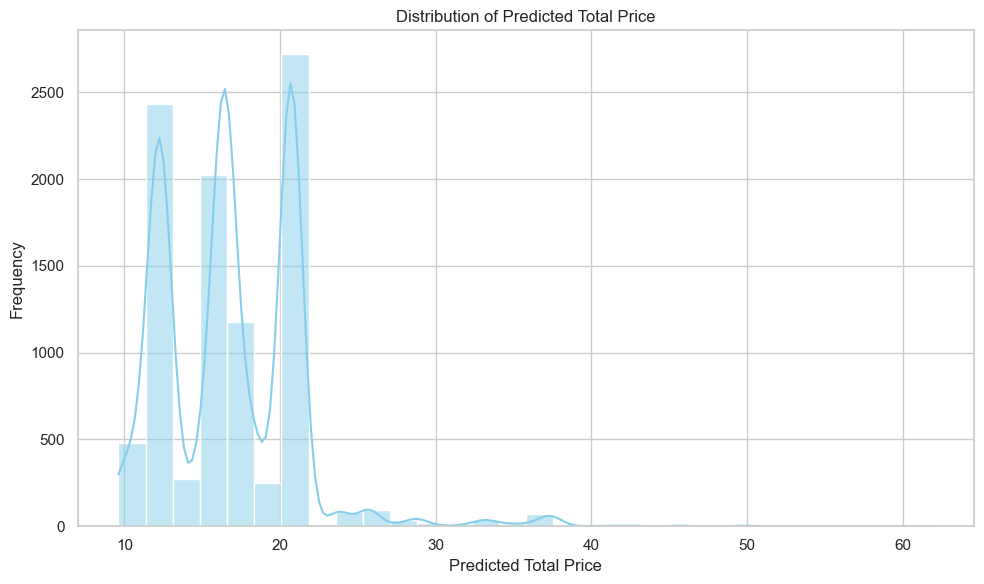

In [63]:
sns.set(style="whitegrid")

# Plot histogram of predicted total prices
plt.figure(figsize=(10, 6))
sns.histplot(y_pred, bins=30, kde=True, color='skyblue')
plt.title('Distribution of Predicted Total Price')
plt.xlabel('Predicted Total Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Here’s the histogram of predicted total prices:

It shows the distribution of sales the model predicted on the test data.

Most predicted orders fall in the $10–$25 range, which makes sense for pizza sales.

The curve is smooth and slightly right-skewed, likely due to larger or combo orders.

